### shapely 3: Mengen, Abstandsbereiche, Hüllen und Voronoi - Übungen

In diesem Notebook verknüpfst du Figuren wie **Mengen** (Schnitt, Vereinigung, Differenz) und konstruierst neue Figuren:
Bereiche mit festem Abstand (Ortslinien), Hüllen um Punktwolken und **Voronoi-Diagramme**, die eine Ebene danach aufteilen,
welcher Punkt am nächsten liegt.

Die Reihe hat vier Notebooks:

1. Grundlagen: Geometrien erstellen, messen und zeichnen
2. Lagebeziehungen: Lage, Schnittpunkte, Abstände
3. **Mengen und Konstruktionen** (dieses Notebook)
4. Abbildungen und Anwendungen: Verschieben, Drehen, Spiegeln, Strecken; Flächen unter Graphen; Monte-Carlo

Wie bisher werden Ergebnisse gerundet ausgegeben.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Wenn etwas vorgegeben ist, steht es schon in der Codezelle.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

## 1. Schnitt, Vereinigung, Differenz

#### Mengenoperationen

Eine Figur ist eine **Punktmenge**. Wie bei Mengen gibt es:

| Methode | Zeichen | Ergebnis |
|---|---|---|
| `a.intersection(b)` | `a & b` | **Schnitt**: Punkte in a **und** b |
| `a.union(b)` | <code>a &#124; b</code> | **Vereinigung**: Punkte in a **oder** b |
| `a.difference(b)` | `a - b` | **Differenz**: Punkte in a, aber nicht in b |
| `a.symmetric_difference(b)` | `a ^ b` | Punkte in **genau einer** der beiden Figuren |

Das Ergebnis ist eine neue Geometrie, oft ein `Polygon`, manchmal ein `MultiPolygon` oder leer.

In [ ]:
from shapely import Polygon

a = Polygon([(0, 0), (4, 0), (4, 3), (0, 3)])
b = Polygon([(2, 1), (6, 1), (6, 5), (2, 5)])
print((a & b).area, (a | b).area, (a - b).area, (b - a).area, (a ^ b).area)
print((a ^ b).geom_type)

#### Ergebnisse ausgeben

Mit welcher Ecke shapely ein Ergebnis-Vieleck beginnt, kann sich je nach Version unterscheiden. `shapely.normalize(g)` bringt eine Geometrie in eine
**feste Normalform** (feste Startecke und Richtung, sortierte Teile). Zum Vergleichen gibt man deshalb `normalize` gerundet aus, oder nur Fläche und Umfang.

In [ ]:
import shapely
from shapely import Polygon

a = Polygon([(0, 0), (4, 0), (4, 3), (0, 3)])
b = Polygon([(2, 1), (6, 1), (6, 5), (2, 5)])
print(shapely.to_wkt(shapely.normalize(a & b), rounding_precision=2))
print(shapely.to_wkt(shapely.normalize(a - b), rounding_precision=2))

#### Aufgabe 1.1

Gib die Flächen von a, b, Schnitt, Vereinigung, a − b und b − a aus.

**Erwartete Ausgabe:**
```
24.0 25.0
6.0 43.0
18.0 19.0
```

In [ ]:
from shapely import Polygon

a = Polygon([(0, 0), (6, 0), (6, 4), (0, 4)])
b = Polygon([(3, 2), (8, 2), (8, 7), (3, 7)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Polygon

a = Polygon([(0, 0), (6, 0), (6, 4), (0, 4)])
b = Polygon([(3, 2), (8, 2), (8, 7), (3, 7)])
print(a.area, b.area)
print((a & b).area, (a | b).area)
print((a - b).area, (b - a).area)
```

</details>

#### Aufgabe 1.2

Prüfe die Formel |A ∪ B| = |A| + |B| − |A ∩ B| für die Flächen von a und b: Gib beide Seiten aus.

**Erwartete Ausgabe:**
```
43.0
43.0
```

In [ ]:
from shapely import Polygon

a = Polygon([(0, 0), (6, 0), (6, 4), (0, 4)])
b = Polygon([(3, 2), (8, 2), (8, 7), (3, 7)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Polygon

a = Polygon([(0, 0), (6, 0), (6, 4), (0, 4)])
b = Polygon([(3, 2), (8, 2), (8, 7), (3, 7)])
print((a | b).area)
print(a.area + b.area - (a & b).area)
```

</details>

#### Aufgabe 1.3

Gib den Schnitt von a und b in Normalform, gerundet auf 2 Stellen, aus.

**Erwartete Ausgabe:**
```
POLYGON ((3 2, 3 4, 6 4, 6 2, 3 2))
```

In [ ]:
import shapely
from shapely import Polygon

a = Polygon([(0, 0), (6, 0), (6, 4), (0, 4)])
b = Polygon([(3, 2), (8, 2), (8, 7), (3, 7)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import Polygon

a = Polygon([(0, 0), (6, 0), (6, 4), (0, 4)])
b = Polygon([(3, 2), (8, 2), (8, 7), (3, 7)])
print(shapely.to_wkt(shapely.normalize(a & b), rounding_precision=2))
```

</details>

#### Aufgabe 1.4

Prüfe, dass die symmetrische Differenz dasselbe ist wie (a − b) ∪ (b − a) und wie (a ∪ b) − (a ∩ b): Gib die drei Flächen aus und ob die Figuren mit `equals` gleich sind.

**Erwartete Ausgabe:**
```
37.0 37.0 37.0
True True
```

In [ ]:
from shapely import Polygon

a = Polygon([(0, 0), (6, 0), (6, 4), (0, 4)])
b = Polygon([(3, 2), (8, 2), (8, 7), (3, 7)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Polygon

a = Polygon([(0, 0), (6, 0), (6, 4), (0, 4)])
b = Polygon([(3, 2), (8, 2), (8, 7), (3, 7)])
s1 = a ^ b
s2 = (a - b) | (b - a)
s3 = (a | b) - (a & b)
print(s1.area, s2.area, s3.area)
print(s1.equals(s2), s1.equals(s3))
```

</details>

#### Aufgabe 1.5

Ein Zimmer (`zimmer`) bekommt einen Teppich (`teppich`). Gib aus, wie viel Teppich auf dem Boden liegt, wie viel vom Boden frei bleibt und wie viel Teppich übersteht
(und umgeklappt werden muss).

**Erwartete Ausgabe:**
```
10.0
10.0
2.5
```

In [ ]:
from shapely import Polygon

zimmer = Polygon([(0, 0), (5, 0), (5, 4), (0, 4)])
teppich = Polygon([(1, 1), (6, 1), (6, 3.5), (1, 3.5)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Polygon

zimmer = Polygon([(0, 0), (5, 0), (5, 4), (0, 4)])
teppich = Polygon([(1, 1), (6, 1), (6, 3.5), (1, 3.5)])
print((zimmer & teppich).area)
print((zimmer - teppich).area)
print((teppich - zimmer).area)
```

</details>

#### Aufgabe 1.6

Zwei Kreise mit Radius 3 haben die Mittelpunkte (0|0) und (4|0) (`buffer(3, quad_segs=64)`). Gib die Fläche der Überlappung (der „Linse“) auf 2 Stellen aus
und die Fläche, die nur von genau einem Kreis bedeckt ist.

**Erwartete Ausgabe:**
```
6.19
44.16
```

In [ ]:
from shapely import Point
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Point
k1 = Point(0, 0).buffer(3, quad_segs=64)
k2 = Point(4, 0).buffer(3, quad_segs=64)
print(round((k1 & k2).area, 2))
print(round((k1 ^ k2).area, 2))
```

</details>

#### Aufgabe 1.7

Aus einem Quadrat 10 × 10 wird ein Kreis mit Radius 3 um den Mittelpunkt ausgeschnitten (`quad_segs=64`). Gib den Typ des Ergebnisses, die Restfläche (2 Stellen) und die Zahl der
Löcher (`interiors`) aus.

**Erwartete Ausgabe:**
```
Polygon
71.73
1
```

In [ ]:
from shapely import Point, Polygon

quadrat = Polygon([(0, 0), (10, 0), (10, 10), (0, 10)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Point, Polygon

quadrat = Polygon([(0, 0), (10, 0), (10, 10), (0, 10)])
rest = quadrat - Point(5, 5).buffer(3, quad_segs=64)
print(rest.geom_type)
print(round(rest.area, 2))
print(len(rest.interiors))
```

</details>

#### Aufgabe 1.8

Ein Rechteck wird von einem senkrechten Streifen durchschnitten. Gib Typ, Zahl der Teile und die Flächen der Teile (sortiert) des Rechtecks ohne den Streifen aus.

**Erwartete Ausgabe:**
```
MultiPolygon 2
[12.0, 20.0]
```

In [ ]:
from shapely import Polygon

rechteck = Polygon([(0, 0), (10, 0), (10, 4), (0, 4)])
streifen = Polygon([(3, -1), (5, -1), (5, 5), (3, 5)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Polygon

rechteck = Polygon([(0, 0), (10, 0), (10, 4), (0, 4)])
streifen = Polygon([(3, -1), (5, -1), (5, 5), (3, 5)])
rest = rechteck - streifen
print(rest.geom_type, len(rest.geoms))
flaechen = []
for teil in rest.geoms:
    flaechen.append(teil.area)
print(sorted(flaechen))
```

</details>

#### Aufgabe 1.9

Zeichne a und b aus der ersten Aufgabe mit `facecolor='none'` (Ränder `'C0'` und `'C1'`, ohne Eckpunkte), den Schnitt rot gefüllt (`facecolor='red'`, `alpha=0.5`) und die
symmetrische Differenz grau gefüllt (`facecolor='gray'`, `alpha=0.3`), beides ohne Eckpunkte. Achsen gleich skaliert, Bildgröße 4 × 4.

**Erwartete Ausgabe:**

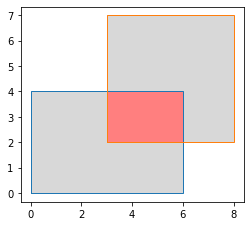

In [ ]:
import matplotlib.pyplot as plt
from shapely.plotting import plot_polygon
from shapely import Polygon

a = Polygon([(0, 0), (6, 0), (6, 4), (0, 4)])
b = Polygon([(3, 2), (8, 2), (8, 7), (3, 7)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
from shapely.plotting import plot_polygon
from shapely import Polygon

a = Polygon([(0, 0), (6, 0), (6, 4), (0, 4)])
b = Polygon([(3, 2), (8, 2), (8, 7), (3, 7)])
fig, ax = plt.subplots(figsize=(4, 4))
plot_polygon(a ^ b, ax=ax, facecolor='gray', alpha=0.3, edgecolor='none', add_points=False)
plot_polygon(a & b, ax=ax, facecolor='red', alpha=0.5, edgecolor='none', add_points=False)
plot_polygon(a, ax=ax, facecolor='none', edgecolor='C0', add_points=False)
plot_polygon(b, ax=ax, facecolor='none', edgecolor='C1', add_points=False)
ax.set_aspect('equal')
plt.show()
```

</details>

#### Aufgabe 1.10

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
from shapely import Polygon

a = Polygon([(0, 0), (2, 0), (2, 2), (0, 2)])
b = Polygon([(1, 0), (3, 0), (3, 2), (1, 2)])
print((a & b).area, (a | b).area, (a - b).area, (a ^ b).area)
print((a & Polygon([(5, 5), (6, 5), (6, 6)])).is_empty)
```

In [ ]:
from shapely import Polygon

a = Polygon([(0, 0), (2, 0), (2, 2), (0, 2)])
b = Polygon([(1, 0), (3, 0), (3, 2), (1, 2)])
print((a & b).area, (a | b).area, (a - b).area, (a ^ b).area)
print((a & Polygon([(5, 5), (6, 5), (6, 6)])).is_empty)

## 2. Viele Flächen vereinigen

#### `union_all`

`shapely.union_all(liste)` vereinigt **alle** Geometrien einer Liste auf einmal. Überlappende Teile werden dabei nur einmal gezählt.
Die Summe der Einzelflächen minus die Fläche der Vereinigung ist die **doppelt bedeckte** Fläche.

In [ ]:
import shapely
from shapely import Polygon

kacheln = [Polygon([(0, 0), (3, 0), (3, 3), (0, 3)]), Polygon([(2, 2), (5, 2), (5, 5), (2, 5)]), Polygon([(4, 0), (6, 0), (6, 2), (4, 2)])]
alle = shapely.union_all(kacheln)
summe = 0
for k in kacheln:
    summe += k.area
print(alle.area, summe, summe - alle.area)
print(alle.geom_type)

#### Aufgabe 2.1

Drei Sprinkler (`sprinkler`, Mittelpunkt und Radius) bewässern Kreise (`quad_segs=64`). Gib die insgesamt bewässerte Fläche (2 Stellen) und die mehrfach bewässerte Fläche (2 Stellen) aus.

**Erwartete Ausgabe:**
```
89.7
17.1
```

In [ ]:
import shapely
from shapely import Point

sprinkler = [((0, 0), 4), ((5, 0), 3), ((2, 4), 3)]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import Point

sprinkler = [((0, 0), 4), ((5, 0), 3), ((2, 4), 3)]
kreise = []
summe = 0
for (x, y), r in sprinkler:
    k = Point(x, y).buffer(r, quad_segs=64)
    kreise.append(k)
    summe += k.area
alle = shapely.union_all(kreise)
print(round(alle.area, 2))
print(round(summe - alle.area, 2))
```

</details>

#### Aufgabe 2.2

Ein Garten (`garten`) soll mit den drei Sprinklern aus der Aufgabe davor bewässert werden. Gib aus, wie viel Prozent des Gartens bewässert werden (1 Stelle).

**Erwartete Ausgabe:**
```
80.2
```

In [ ]:
import shapely
from shapely import Point, Polygon

sprinkler = [((0, 0), 4), ((5, 0), 3), ((2, 4), 3)]
garten = Polygon([(-3, -3), (8, -3), (8, 6), (-3, 6)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import Point, Polygon

sprinkler = [((0, 0), 4), ((5, 0), 3), ((2, 4), 3)]
garten = Polygon([(-3, -3), (8, -3), (8, 6), (-3, 6)])
kreise = []
for (x, y), r in sprinkler:
    kreise.append(Point(x, y).buffer(r, quad_segs=64))
bewaessert = shapely.union_all(kreise) & garten
print(round(bewaessert.area / garten.area * 100, 1))
```

</details>

#### Aufgabe 2.3

Vier Grundstücke grenzen aneinander. Vereinige sie zu einem Gebiet und gib Fläche, Umfang und Typ aus. (An den gemeinsamen Grenzen entsteht kein Rand mehr.)

**Erwartete Ausgabe:**
```
1012.5 125.81 Polygon
```

In [ ]:
import shapely
from shapely import Polygon

grundstuecke = [Polygon([(0, 0), (20, 0), (20, 15), (0, 15)]), Polygon([(20, 0), (35, 0), (35, 15), (20, 15)]),
                Polygon([(0, 15), (20, 15), (20, 30), (0, 30)]), Polygon([(20, 15), (35, 15), (30, 30), (20, 30)])]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import Polygon

grundstuecke = [Polygon([(0, 0), (20, 0), (20, 15), (0, 15)]), Polygon([(20, 0), (35, 0), (35, 15), (20, 15)]),
                Polygon([(0, 15), (20, 15), (20, 30), (0, 30)]), Polygon([(20, 15), (35, 15), (30, 30), (20, 30)])]
g = shapely.union_all(grundstuecke)
print(g.area, round(g.length, 2), g.geom_type)
```

</details>

#### Aufgabe 2.4

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
import shapely
from shapely import Polygon

q = [Polygon([(0, 0), (2, 0), (2, 2), (0, 2)]), Polygon([(1, 1), (3, 1), (3, 3), (1, 3)]), Polygon([(5, 5), (6, 5), (6, 6), (5, 6)])]
u = shapely.union_all(q)
print(u.area, u.geom_type, len(u.geoms))
```

In [ ]:
import shapely
from shapely import Polygon

q = [Polygon([(0, 0), (2, 0), (2, 2), (0, 2)]), Polygon([(1, 1), (3, 1), (3, 3), (1, 3)]), Polygon([(5, 5), (6, 5), (6, 6), (5, 6)])]
u = shapely.union_all(q)
print(u.area, u.geom_type, len(u.geoms))

## 3. Abstandsbereiche: buffer

#### Ortslinien

`g.buffer(r)` ist die Menge aller Punkte, die von `g` **höchstens den Abstand r** haben:

- um einen **Punkt**: ein Kreis (genauer ein Vieleck mit vielen Ecken, siehe Notebook 1),
- um eine **Strecke**: ein „Stadion“, zwei Halbkreise und ein Rechteck. Fläche: 2r·l + πr²,
- um ein **Vieleck**: das Vieleck mit abgerundet vergrößertem Rand.

Mit **negativem** r wird ein Vieleck nach innen verkleinert. `cap_style='flat'` schneidet die Enden einer Strecke gerade ab.

In [ ]:
import math
from shapely import Point, LineString, Polygon

s = LineString([(0, 0), (10, 0)])
stadion = s.buffer(2, quad_segs=64)
print(round(stadion.area, 2), round(2 * 2 * 10 + math.pi * 2 ** 2, 2))
print(round(s.buffer(2, cap_style='flat').area, 2))
q = Polygon([(0, 0), (10, 0), (10, 6), (0, 6)])
print(q.buffer(-1).area)

#### Aufgabe 3.1

Um eine 400 m lange gerade Straße (`strasse`) gilt ein 50 m breiter Lärmschutzstreifen auf jeder Seite (Halbkreise an den Enden, `quad_segs=64`). Gib die Fläche des Streifens in m²
(ganzzahlig gerundet) und den Wert der Stadion-Formel aus.

**Erwartete Ausgabe:**
```
47853
47854
```

In [ ]:
import math
from shapely import LineString

strasse = LineString([(0, 0), (400, 0)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import math
from shapely import LineString

strasse = LineString([(0, 0), (400, 0)])
zone = strasse.buffer(50, quad_segs=64)
print(round(zone.area))
print(round(2 * 50 * 400 + math.pi * 50 ** 2))
```

</details>

#### Aufgabe 3.2

Welche Häuser liegen höchstens 100 m von der Stromleitung (Streckenzug `leitung`) entfernt? Gib ihre Namen aus. Löse es einmal mit `buffer` + `covers` und einmal mit `distance`.

**Erwartete Ausgabe:**
```
A C E 
A C E
```

In [ ]:
from shapely import Point, LineString

leitung = LineString([(0, 0), (300, 100), (600, 50)])
haeuser = {'A': Point(100, 120), 'B': Point(300, 250), 'C': Point(550, 0), 'D': Point(700, 60), 'E': Point(250, 40)}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Point, LineString

leitung = LineString([(0, 0), (300, 100), (600, 50)])
haeuser = {'A': Point(100, 120), 'B': Point(300, 250), 'C': Point(550, 0), 'D': Point(700, 60), 'E': Point(250, 40)}
zone = leitung.buffer(100, quad_segs=64)
for name, h in haeuser.items():
    if zone.covers(h):
        print(name, end=' ')
print()
for name, h in haeuser.items():
    if h.distance(leitung) <= 100:
        print(name, end=' ')
print()
```

</details>

#### Aufgabe 3.3

Ein rechteckiges Beet (8 m × 5 m) wird ringsum von einem 1 m breiten Weg mit **runden** Ecken umgeben (`buffer(1, quad_segs=64)`). Gib die Fläche des Weges (2 Stellen) aus.
Zum Vergleich: Ein Weg mit eckigen Ecken (`join_style='mitre'`) hat die Fläche (8+2)·(5+2) − 8·5.

**Erwartete Ausgabe:**
```
29.14
30.0 30
```

In [ ]:
from shapely import Polygon

beet = Polygon([(0, 0), (8, 0), (8, 5), (0, 5)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Polygon

beet = Polygon([(0, 0), (8, 0), (8, 5), (0, 5)])
rund = beet.buffer(1, quad_segs=64) - beet
eckig = beet.buffer(1, join_style='mitre') - beet
print(round(rund.area, 2))
print(eckig.area, (8 + 2) * (5 + 2) - 8 * 5)
```

</details>

#### Aufgabe 3.4

Ein Spielfeld (`feld`) hat einen 2 m breiten Sicherheitsrand nach innen. Gib die Fläche der nutzbaren Innenfläche (`buffer(-2)`) und die Fläche des Randes aus.

**Erwartete Ausgabe:**
```
576.0
224.0
```

In [ ]:
from shapely import Polygon

feld = Polygon([(0, 0), (40, 0), (40, 20), (0, 20)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Polygon

feld = Polygon([(0, 0), (40, 0), (40, 20), (0, 20)])
innen = feld.buffer(-2)
print(innen.area)
print(feld.area - innen.area)
```

</details>

#### Aufgabe 3.5

Zeichne die Strecke von (0|0) nach (6|2) (`'black'`, ohne Eckpunkte) und ihren Abstandsbereich mit r = 1 (Füllung `'lightblue'`, Rand `'C0'`, ohne Eckpunkte, `quad_segs=32`).
Achsen gleich skaliert, Bildgröße 4 × 3.

**Erwartete Ausgabe:**

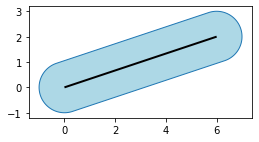

In [ ]:
import matplotlib.pyplot as plt
from shapely import LineString
from shapely.plotting import plot_line, plot_polygon
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
from shapely import LineString
from shapely.plotting import plot_line, plot_polygon
s = LineString([(0, 0), (6, 2)])
fig, ax = plt.subplots(figsize=(4, 3))
plot_polygon(s.buffer(1, quad_segs=32), ax=ax, facecolor='lightblue', edgecolor='C0', add_points=False)
plot_line(s, ax=ax, color='black', add_points=False)
ax.set_aspect('equal')
plt.show()
```

</details>

#### Aufgabe 3.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
from shapely import Polygon

q = Polygon([(0, 0), (4, 0), (4, 4), (0, 4)])
print(q.buffer(-1).area)
print(q.buffer(-2).is_empty)
print(q.buffer(1, join_style='mitre').area)
```

In [ ]:
from shapely import Polygon

q = Polygon([(0, 0), (4, 0), (4, 4), (0, 4)])
print(q.buffer(-1).area)
print(q.buffer(-2).is_empty)
print(q.buffer(1, join_style='mitre').area)

## 4. Hüllen

#### Hüllen um Punkte und Figuren

| Aufruf | Ergebnis |
|---|---|
| `g.convex_hull` | **konvexe Hülle**: das kleinste konvexe Vieleck, das g enthält („Gummiband um die Punkte“) |
| `g.envelope` | das umgebende achsenparallele Rechteck (wie `bounds`) |
| `g.minimum_rotated_rectangle` | das kleinste umgebende Rechteck, auch schräg |
| `shapely.minimum_bounding_circle(g)` | der kleinste umgebende Kreis (als Vieleck) |
| `shapely.minimum_bounding_radius(g)` | sein Radius |

Ein Vieleck ist **konvex**, wenn es mit seiner konvexen Hülle übereinstimmt.

In [ ]:
import shapely
from shapely import MultiPoint, Polygon

punkte = MultiPoint([(0, 0), (4, 1), (2, 2), (1, 4), (5, 5), (3, 3)])
h = punkte.convex_hull
print(shapely.to_wkt(shapely.normalize(h), rounding_precision=2))
print(h.area, punkte.envelope.area)
print(round(shapely.minimum_bounding_radius(punkte), 4))
l = Polygon([(0, 0), (4, 0), (4, 1), (1, 1), (1, 3), (0, 3)])
print(l.equals(l.convex_hull), round(l.convex_hull.area, 2))

#### Aufgabe 4.1

Ein Zaun soll alle Bäume in `baeume` einschließen und möglichst kurz sein: Das ist die konvexe Hülle. Gib Länge (2 Stellen) und Fläche des Zauns aus und wie viele Bäume **auf** dem
Zaun stehen (Eckpunkte der Hülle).

**Erwartete Ausgabe:**
```
24.67 41.0
5
```

In [ ]:
import shapely
from shapely import MultiPoint

baeume = MultiPoint([(2, 1), (7, 2), (9, 6), (5, 9), (1, 6), (4, 4), (6, 5), (3, 7)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import MultiPoint

baeume = MultiPoint([(2, 1), (7, 2), (9, 6), (5, 9), (1, 6), (4, 4), (6, 5), (3, 7)])
zaun = baeume.convex_hull
print(round(zaun.length, 2), zaun.area)
print(len(zaun.exterior.coords) - 1)
```

</details>

#### Aufgabe 4.2

Gib die Fläche des achsenparallelen umgebenden Rechtecks (`envelope`) der Bäume, des kleinsten schrägen Rechtecks (`minimum_rotated_rectangle`, 2 Stellen) und der konvexen Hülle aus.

**Erwartete Ausgabe:**
```
64.0
56.92
41.0
```

In [ ]:
import shapely
from shapely import MultiPoint

baeume = MultiPoint([(2, 1), (7, 2), (9, 6), (5, 9), (1, 6), (4, 4), (6, 5), (3, 7)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import MultiPoint

baeume = MultiPoint([(2, 1), (7, 2), (9, 6), (5, 9), (1, 6), (4, 4), (6, 5), (3, 7)])
print(baeume.envelope.area)
print(round(baeume.minimum_rotated_rectangle.area, 2))
print(baeume.convex_hull.area)
```

</details>

#### Aufgabe 4.3

Ein Sendemast soll alle Häuser erreichen und so wenig Reichweite wie möglich brauchen: Er steht im Mittelpunkt des kleinsten umgebenden Kreises. Gib den Radius (2 Stellen) und den
Mittelpunkt (gerundet, mit `centroid` des Kreises) aus.

**Erwartete Ausgabe:**
```
4.33
POINT (4 1.67)
```

In [ ]:
import shapely
from shapely import MultiPoint

haeuser = MultiPoint([(0, 0), (8, 0), (4, 6), (3, 2)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import MultiPoint

haeuser = MultiPoint([(0, 0), (8, 0), (4, 6), (3, 2)])
kreis = shapely.minimum_bounding_circle(haeuser)
print(round(shapely.minimum_bounding_radius(haeuser), 2))
print(shapely.to_wkt(kreis.centroid, rounding_precision=2))
```

</details>

#### Aufgabe 4.4

Gib für jedes Vieleck in `vielecke` aus, ob es konvex ist.

**Erwartete Ausgabe:**
```
Quadrat True
Pfeil False
Sechseck True
Stern False
```

In [ ]:
from shapely import Polygon

vielecke = {'Quadrat': Polygon([(0, 0), (2, 0), (2, 2), (0, 2)]), 'Pfeil': Polygon([(0, 0), (2, 1), (0, 2), (1, 1)]),
            'Sechseck': Polygon([(1, 0), (3, 0), (4, 2), (3, 4), (1, 4), (0, 2)]), 'Stern': Polygon([(0, 2), (1.5, 1.5), (2, 0), (2.5, 1.5), (4, 2), (2.5, 2.5), (2, 4), (1.5, 2.5)])}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Polygon

vielecke = {'Quadrat': Polygon([(0, 0), (2, 0), (2, 2), (0, 2)]), 'Pfeil': Polygon([(0, 0), (2, 1), (0, 2), (1, 1)]),
            'Sechseck': Polygon([(1, 0), (3, 0), (4, 2), (3, 4), (1, 4), (0, 2)]), 'Stern': Polygon([(0, 2), (1.5, 1.5), (2, 0), (2.5, 1.5), (4, 2), (2.5, 2.5), (2, 4), (1.5, 2.5)])}
for name, v in vielecke.items():
    print(name, v.equals(v.convex_hull))
```

</details>

#### Aufgabe 4.5

Zeichne die Bäume als grüne Punkte, ihre konvexe Hülle (Füllung `'lightgreen'`, `alpha=0.4`, Rand `'green'`, ohne Eckpunkte) und das kleinste umgebende Rechteck
(nur Rand `'gray'`, `facecolor='none'`, ohne Eckpunkte). Achsen gleich skaliert, Bildgröße 4 × 4.

**Erwartete Ausgabe:**

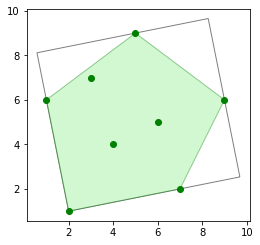

In [ ]:
import matplotlib.pyplot as plt
from shapely.plotting import plot_points, plot_polygon
import shapely
from shapely import MultiPoint

baeume = MultiPoint([(2, 1), (7, 2), (9, 6), (5, 9), (1, 6), (4, 4), (6, 5), (3, 7)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
from shapely.plotting import plot_points, plot_polygon
import shapely
from shapely import MultiPoint

baeume = MultiPoint([(2, 1), (7, 2), (9, 6), (5, 9), (1, 6), (4, 4), (6, 5), (3, 7)])
fig, ax = plt.subplots(figsize=(4, 4))
plot_polygon(baeume.minimum_rotated_rectangle, ax=ax, facecolor='none', edgecolor='gray', add_points=False)
plot_polygon(baeume.convex_hull, ax=ax, facecolor='lightgreen', alpha=0.4, edgecolor='green', add_points=False)
plot_points(baeume, ax=ax, color='green')
ax.set_aspect('equal')
plt.show()
```

</details>

#### Aufgabe 4.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
from shapely import MultiPoint

m = MultiPoint([(0, 0), (4, 0), (4, 4), (0, 4), (2, 2), (1, 3)])
h = m.convex_hull
print(h.area, len(h.exterior.coords) - 1)
print(m.envelope.area)
```

In [ ]:
from shapely import MultiPoint

m = MultiPoint([(0, 0), (4, 0), (4, 4), (0, 4), (2, 2), (1, 3)])
h = m.convex_hull
print(h.area, len(h.exterior.coords) - 1)
print(m.envelope.area)

## 5. Voronoi-Diagramme

#### Wer ist am nächsten?

Gegeben sind einige Punkte, zum Beispiel Schulen. Das **Voronoi-Diagramm** teilt die Ebene in **Zellen**: Jede Zelle enthält alle Orte, für die eine bestimmte Schule
die **nächste** ist.

Für zwei Punkte A und B ist die Grenze die **Mittelsenkrechte** der Strecke AB: Auf ihr ist man von A und B gleich weit entfernt. Bei mehr Punkten bestehen die Grenzen aus
Stücken von Mittelsenkrechten. Dort, wo drei Zellen zusammenstoßen, ist man von drei Punkten gleich weit entfernt: Das ist der **Umkreismittelpunkt** dieser drei Punkte.

In [ ]:
import shapely
from shapely import MultiPoint, Polygon

punkte = MultiPoint([(0, 0), (4, 0)])
gebiet = Polygon([(-2, -2), (6, -2), (6, 2), (-2, 2)])
zellen = shapely.voronoi_polygons(punkte, extend_to=gebiet, ordered=True)
for z in zellen.geoms:
    print(shapely.to_wkt(shapely.normalize(z & gebiet), rounding_precision=2))

#### `voronoi_polygons`

`shapely.voronoi_polygons(punkte, extend_to=gebiet, ordered=True)`

- `punkte` ist ein `MultiPoint`. Das Ergebnis ist eine Sammlung (`GeometryCollection`) von Vielecken; `geoms` enthält die Zellen.
- `ordered=True`: Die Zellen stehen in **derselben Reihenfolge wie die Punkte**. Die erste Zelle gehört zum ersten Punkt usw.
- Die äußeren Zellen sind eigentlich unendlich groß. `extend_to=gebiet` sorgt dafür, dass sie mindestens das Gebiet abdecken. Mit `zelle & gebiet`
  schneidet man sie auf das Gebiet zu.

In [ ]:
import shapely
from shapely import MultiPoint, Point, Polygon

schulen = [(1, 1), (7, 2), (4, 6)]
gebiet = Polygon([(0, 0), (8, 0), (8, 8), (0, 8)])
zellen = shapely.voronoi_polygons(MultiPoint(schulen), extend_to=gebiet, ordered=True)
for schule, zelle in zip(schulen, zellen.geoms):
    print(schule, round((zelle & gebiet).area, 2))
ort = Point(5, 3)
for i in range(len(schulen)):
    if zellen.geoms[i].contains(ort):
        print('nächste Schule:', schulen[i])

`geoms[i]` gibt das i-te Teil einer mehrteiligen Geometrie zurück, wie bei einer Liste.

In [ ]:
from shapely import MultiPoint

print(MultiPoint([(0, 0), (3, 4)]).geoms[1])

#### Aufgabe 5.1

Bestimme die Voronoi-Zellen der Schulen in `schulen` im Gebiet. Gib für jede Schule den Namen und die Fläche ihrer Zelle im Gebiet (2 Stellen) aus. (Die Reihenfolge der Schulen im
Dictionary ist die Reihenfolge der Punkte.) Gib zur Kontrolle die Summe der Flächen aus.

**Erwartete Ausgabe:**
```
Goethe 27.74
Schiller 39.25
Kepler 45.31
Hesse 31.7
144.0
```

In [ ]:
import shapely
from shapely import MultiPoint, Point, Polygon

schulen = {'Goethe': (2, 2), 'Schiller': (8, 3), 'Kepler': (5, 8), 'Hesse': (9, 9)}
gebiet = Polygon([(0, 0), (12, 0), (12, 12), (0, 12)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import MultiPoint, Point, Polygon

schulen = {'Goethe': (2, 2), 'Schiller': (8, 3), 'Kepler': (5, 8), 'Hesse': (9, 9)}
gebiet = Polygon([(0, 0), (12, 0), (12, 12), (0, 12)])
namen = list(schulen)
zellen = shapely.voronoi_polygons(MultiPoint(list(schulen.values())), extend_to=gebiet, ordered=True)
summe = 0
for name, zelle in zip(namen, zellen.geoms):
    a = (zelle & gebiet).area
    summe += a
    print(name, round(a, 2))
print(round(summe, 2))
```

</details>

#### Aufgabe 5.2

Zu welcher Schule gehören die Schüler in `wohnorte`? Bestimme die Zelle, in der der Wohnort liegt, und gib Name des Schülers und der Schule aus. Prüfe zur Kontrolle mit `distance`, dass
es wirklich die nächste Schule ist (gib den Namen der nächsten Schule nach `distance` dahinter aus).

**Erwartete Ausgabe:**
```
Ali Kepler Kepler
Bea Hesse Hesse
Cem Schiller Schiller
Dana Hesse Hesse
```

In [ ]:
import shapely
from shapely import MultiPoint, Point, Polygon

schulen = {'Goethe': (2, 2), 'Schiller': (8, 3), 'Kepler': (5, 8), 'Hesse': (9, 9)}
gebiet = Polygon([(0, 0), (12, 0), (12, 12), (0, 12)])
wohnorte = {'Ali': (3, 6), 'Bea': (10, 6), 'Cem': (6, 1), 'Dana': (11, 11)}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import MultiPoint, Point, Polygon

schulen = {'Goethe': (2, 2), 'Schiller': (8, 3), 'Kepler': (5, 8), 'Hesse': (9, 9)}
gebiet = Polygon([(0, 0), (12, 0), (12, 12), (0, 12)])
wohnorte = {'Ali': (3, 6), 'Bea': (10, 6), 'Cem': (6, 1), 'Dana': (11, 11)}
namen = list(schulen)
zellen = shapely.voronoi_polygons(MultiPoint(list(schulen.values())), extend_to=gebiet, ordered=True)
for kind, ort in wohnorte.items():
    p = Point(ort)
    for i in range(len(namen)):
        if zellen.geoms[i].contains(p):
            zelle_von = namen[i]
    naechste = min(namen, key=lambda n: p.distance(Point(schulen[n])))
    print(kind, zelle_von, naechste)
```

</details>

#### Aufgabe 5.3

Zeige, dass die Grenze zwischen den Zellen von A(1|1) und B(5|3) auf der Mittelsenkrechten liegt: Bestimme die gemeinsame Grenze der beiden Zellen (`zelle_a & zelle_b`, eine Strecke).
Gib für ihre beiden Endpunkte die Abstände zu A und zu B (4 Stellen) aus.

**Erwartete Ausgabe:**
```
5.0 5.0
5.0 5.0
```

In [ ]:
import shapely
from shapely import MultiPoint, Point, Polygon

A = Point(1, 1)
B = Point(5, 3)
gebiet = Polygon([(-2, -2), (8, -2), (8, 6), (-2, 6)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import MultiPoint, Point, Polygon

A = Point(1, 1)
B = Point(5, 3)
gebiet = Polygon([(-2, -2), (8, -2), (8, 6), (-2, 6)])
zellen = shapely.voronoi_polygons(MultiPoint([A, B]), extend_to=gebiet, ordered=True)
grenze = (zellen.geoms[0] & zellen.geoms[1]) & gebiet
for x, y in grenze.coords:
    p = Point(x, y)
    print(round(p.distance(A), 4), round(p.distance(B), 4))
```

</details>

#### Aufgabe 5.4

Drei Dörfer A(0|0), B(8|0), C(2|6) wollen einen gemeinsamen Brunnen, der von allen gleich weit entfernt ist. Das ist die Ecke, an der die drei Voronoi-Zellen zusammenstoßen.
Bestimme den Schnitt aller drei Zellen (ein Punkt) und gib ihn gerundet und seine Abstände zu A, B, C (4 Stellen) aus.

**Erwartete Ausgabe:**
```
POINT (4 2)
4.4721
4.4721
4.4721
```

In [ ]:
import shapely
from shapely import MultiPoint, Point, Polygon

doerfer = [Point(0, 0), Point(8, 0), Point(2, 6)]
gebiet = Polygon([(-5, -5), (12, -5), (12, 10), (-5, 10)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import MultiPoint, Point, Polygon

doerfer = [Point(0, 0), Point(8, 0), Point(2, 6)]
gebiet = Polygon([(-5, -5), (12, -5), (12, 10), (-5, 10)])
zellen = shapely.voronoi_polygons(MultiPoint(doerfer), extend_to=gebiet, ordered=True)
brunnen = zellen.geoms[0] & zellen.geoms[1] & zellen.geoms[2]
print(shapely.to_wkt(brunnen, rounding_precision=2))
for d in doerfer:
    print(round(brunnen.distance(d), 4))
```

</details>

#### Aufgabe 5.5

Prüfe den Brunnen aus der Aufgabe davor: Der Umkreismittelpunkt eines Dreiecks ist der Schnittpunkt zweier Mittelsenkrechten. Die Mittelsenkrechte von AB ist hier x = 4.
Die Mittelsenkrechte von AC geht durch die Mitte (1|3) und steht senkrecht auf AC, hat also die Steigung −1/3. Erzeuge beide als lange Strecken und gib ihren Schnittpunkt gerundet aus.

**Erwartete Ausgabe:**
```
POINT (4 2)
```

In [ ]:
import shapely
from shapely import LineString
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import LineString
ms_ab = LineString([(4, -100), (4, 100)])
ms_ac = LineString([(-100, 3 - (-100 - 1) / 3), (100, 3 - (100 - 1) / 3)])
print(shapely.to_wkt(ms_ab & ms_ac, rounding_precision=2))
```

</details>

#### Aufgabe 5.6

Zeichne das Voronoi-Diagramm der Schulen im Gebiet: jede Zelle (mit dem Gebiet geschnitten) in einer eigenen Farbe (`'C0'`, `'C1'`, `'C2'`, `'C3'`, `alpha=0.4`, Rand `'black'`, ohne Eckpunkte)
und die Schulen als schwarze Punkte. Achsen gleich skaliert, Bildgröße 4 × 4.

**Erwartete Ausgabe:**

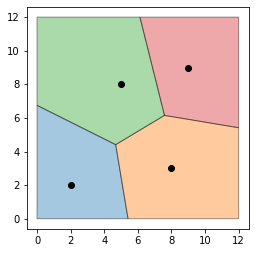

In [ ]:
import matplotlib.pyplot as plt
from shapely.plotting import plot_points, plot_polygon
import shapely
from shapely import MultiPoint, Point, Polygon

schulen = {'Goethe': (2, 2), 'Schiller': (8, 3), 'Kepler': (5, 8), 'Hesse': (9, 9)}
gebiet = Polygon([(0, 0), (12, 0), (12, 12), (0, 12)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
from shapely.plotting import plot_points, plot_polygon
import shapely
from shapely import MultiPoint, Point, Polygon

schulen = {'Goethe': (2, 2), 'Schiller': (8, 3), 'Kepler': (5, 8), 'Hesse': (9, 9)}
gebiet = Polygon([(0, 0), (12, 0), (12, 12), (0, 12)])
zellen = shapely.voronoi_polygons(MultiPoint(list(schulen.values())), extend_to=gebiet, ordered=True)
fig, ax = plt.subplots(figsize=(4, 4))
for i in range(len(zellen.geoms)):
    plot_polygon(zellen.geoms[i] & gebiet, ax=ax, facecolor=f'C{i}', alpha=0.4, edgecolor='black', add_points=False)
plot_points(MultiPoint(list(schulen.values())), ax=ax, color='black')
ax.set_aspect('equal')
plt.show()
```

</details>

#### Aufgabe 5.7

Eine neue Schule `Curie` bei (5|4) kommt dazu. Gib für alle Schulen die Fläche ihrer Zelle im Gebiet vorher und nachher aus (2 Stellen), in der Form `Goethe 30.5 24.0`,
und für Curie nur die neue Fläche.

**Erwartete Ausgabe:**
```
Goethe 27.74 21.56
Schiller 39.25 33.06
Kepler 45.31 40.67
Hesse 31.7 31.7
Curie 17.01
```

In [ ]:
import shapely
from shapely import MultiPoint, Point, Polygon

schulen = {'Goethe': (2, 2), 'Schiller': (8, 3), 'Kepler': (5, 8), 'Hesse': (9, 9)}
gebiet = Polygon([(0, 0), (12, 0), (12, 12), (0, 12)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import MultiPoint, Point, Polygon

schulen = {'Goethe': (2, 2), 'Schiller': (8, 3), 'Kepler': (5, 8), 'Hesse': (9, 9)}
gebiet = Polygon([(0, 0), (12, 0), (12, 12), (0, 12)])
def flaechen(orte):
    zellen = shapely.voronoi_polygons(MultiPoint(orte), extend_to=gebiet, ordered=True)
    ergebnis = []
    for z in zellen.geoms:
        ergebnis.append(round((z & gebiet).area, 2))
    return ergebnis

vorher = flaechen(list(schulen.values()))
nachher = flaechen(list(schulen.values()) + [(5, 4)])
for i, name in enumerate(schulen):
    print(name, vorher[i], nachher[i])
print('Curie', nachher[-1])
```

</details>

#### Aufgabe 5.8

Ein Eiswagen-Unternehmen hat Wagen an den Standorten in `wagen`. Am Strand (`strand`, ein Rechteck) gehen Kunden immer zum nächsten Wagen. Welcher Wagen hat das größte
Einzugsgebiet am Strand? Gib alle Flächen (2 Stellen) und dann den Index des Wagens mit der größten Fläche aus.

**Erwartete Ausgabe:**
```
[300.6, 360.4, 269.0, 270.0]
1
```

In [ ]:
import shapely
from shapely import MultiPoint, Polygon

wagen = [(10, 5), (40, 8), (70, 3), (85, 9)]
strand = Polygon([(0, 0), (100, 0), (100, 12), (0, 12)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import MultiPoint, Polygon

wagen = [(10, 5), (40, 8), (70, 3), (85, 9)]
strand = Polygon([(0, 0), (100, 0), (100, 12), (0, 12)])
zellen = shapely.voronoi_polygons(MultiPoint(wagen), extend_to=strand, ordered=True)
flaechen = []
for z in zellen.geoms:
    flaechen.append(round((z & strand).area, 2))
print(flaechen)
print(flaechen.index(max(flaechen)))
```

</details>

#### Aufgabe 5.9

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
import shapely
from shapely import MultiPoint, Polygon

gebiet = Polygon([(0, 0), (10, 0), (10, 4), (0, 4)])
zellen = shapely.voronoi_polygons(MultiPoint([(2, 2), (8, 2)]), extend_to=gebiet, ordered=True)
for z in zellen.geoms:
    print((z & gebiet).area)
```

In [ ]:
import shapely
from shapely import MultiPoint, Polygon

gebiet = Polygon([(0, 0), (10, 0), (10, 4), (0, 4)])
zellen = shapely.voronoi_polygons(MultiPoint([(2, 2), (8, 2)]), extend_to=gebiet, ordered=True)
for z in zellen.geoms:
    print((z & gebiet).area)

## 6. Ausblick: Delaunay-Dreiecke

#### Dreiecksnetze

Verbindet man die Punkte, deren Voronoi-Zellen aneinandergrenzen, entsteht ein Netz aus Dreiecken: die **Delaunay-Triangulierung**.
Sie hat eine schöne Eigenschaft: Im **Umkreis** jedes Dreiecks liegt kein anderer Punkt. Dadurch vermeidet sie sehr spitze Dreiecke.
Sie wird z. B. benutzt, um aus Höhenmesspunkten ein Geländemodell zu bauen.

`shapely.delaunay_triangles(punkte)` gibt die Dreiecke zurück, `only_edges=True` nur die Kanten. Zusammen bedecken die Dreiecke genau die konvexe Hülle.

In [ ]:
import shapely
from shapely import MultiPoint

punkte = MultiPoint([(0, 0), (4, 0), (2, 3), (5, 4), (1, 5)])
dreiecke = shapely.delaunay_triangles(punkte)
print(len(dreiecke.geoms))
summe = 0
for d in dreiecke.geoms:
    summe += d.area
print(summe, punkte.convex_hull.area)
print(len(shapely.delaunay_triangles(punkte, only_edges=True).geoms))

#### Aufgabe 6.1

Gib für die Messpunkte in `punkte` die Anzahl der Delaunay-Dreiecke, die Anzahl der Kanten und die Gesamtlänge aller Kanten (2 Stellen) aus.

**Erwartete Ausgabe:**
```
6
12
51.62
```

In [ ]:
import shapely
from shapely import MultiPoint

punkte = MultiPoint([(0, 0), (6, 0), (3, 2), (7, 5), (1, 6), (4, 7), (8, 2)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import MultiPoint

punkte = MultiPoint([(0, 0), (6, 0), (3, 2), (7, 5), (1, 6), (4, 7), (8, 2)])
dreiecke = shapely.delaunay_triangles(punkte)
kanten = shapely.delaunay_triangles(punkte, only_edges=True)
print(len(dreiecke.geoms))
print(len(kanten.geoms))
print(round(kanten.length, 2))
```

</details>

#### Aufgabe 6.2

Zeichne die Delaunay-Dreiecke der Punkte aus der Aufgabe davor (Füllung `'lightyellow'`, Rand `'orange'`, ohne Eckpunkte) und die Punkte schwarz. Achsen gleich skaliert, Bildgröße 4 × 4.

**Erwartete Ausgabe:**

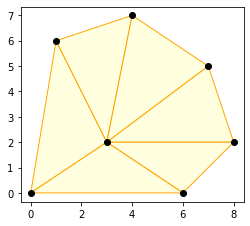

In [ ]:
import matplotlib.pyplot as plt
import shapely
from shapely import MultiPoint
from shapely.plotting import plot_points, plot_polygon

punkte = MultiPoint([(0, 0), (6, 0), (3, 2), (7, 5), (1, 6), (4, 7), (8, 2)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import shapely
from shapely import MultiPoint
from shapely.plotting import plot_points, plot_polygon

punkte = MultiPoint([(0, 0), (6, 0), (3, 2), (7, 5), (1, 6), (4, 7), (8, 2)])
fig, ax = plt.subplots(figsize=(4, 4))
for d in shapely.delaunay_triangles(punkte).geoms:
    plot_polygon(d, ax=ax, facecolor='lightyellow', edgecolor='orange', add_points=False)
plot_points(punkte, ax=ax, color='black')
ax.set_aspect('equal')
plt.show()
```

</details>

## 7. Gemischte Übungen

#### Aufgabe 7.1

Ein Funkmast (Punkt (0|0)) reicht 5 km weit, ein zweiter (Punkt (6|2)) 4 km (`quad_segs=64`). Ein Gebiet ist das Rechteck von (−4|−4) bis (10|6). Gib aus, welcher Anteil des Gebiets
(in Prozent, 1 Stelle) **keinen** Empfang hat.

**Erwartete Ausgabe:**
```
22.2
```

In [ ]:
import shapely
from shapely import Point, Polygon

gebiet = Polygon([(-4, -4), (10, -4), (10, 6), (-4, 6)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import Point, Polygon

gebiet = Polygon([(-4, -4), (10, -4), (10, 6), (-4, 6)])
empfang = shapely.union_all([Point(0, 0).buffer(5, quad_segs=64), Point(6, 2).buffer(4, quad_segs=64)])
ohne = gebiet - empfang
print(round(ohne.area / gebiet.area * 100, 1))
```

</details>

#### Aufgabe 7.2

Feuerwachen sollen jeweils für die Orte zuständig sein, für die sie am nächsten sind (Voronoi). Eine Wache schafft höchstens 6 km Anfahrt. Gib für jede Wache den Anteil ihrer Zelle im
Gebiet aus, der weiter als 6 km entfernt ist (Prozent, 1 Stelle; `buffer(6, quad_segs=64)`).

**Erwartete Ausgabe:**
```
(4, 4) 6.4
(14, 6) 23.8
(8, 14) 39.0
```

In [ ]:
import shapely
from shapely import MultiPoint, Point, Polygon

wachen = [(4, 4), (14, 6), (8, 14)]
gebiet = Polygon([(0, 0), (20, 0), (20, 20), (0, 20)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import MultiPoint, Point, Polygon

wachen = [(4, 4), (14, 6), (8, 14)]
gebiet = Polygon([(0, 0), (20, 0), (20, 20), (0, 20)])
zellen = shapely.voronoi_polygons(MultiPoint(wachen), extend_to=gebiet, ordered=True)
for (x, y), zelle in zip(wachen, zellen.geoms):
    z = zelle & gebiet
    zu_weit = z - Point(x, y).buffer(6, quad_segs=64)
    print((x, y), round(zu_weit.area / z.area * 100, 1))
```

</details>

#### Aufgabe 7.3

Drei Bäume (`baeume`) werfen kreisförmige Schatten (Radius in `radien`, `quad_segs=64`). Eine Terrasse ist das Rechteck von (0|0) bis (6|4). Gib aus, wie viel Prozent der Terrasse im
Schatten liegen (1 Stelle), und welcher Baum allein die meiste Terrassenfläche beschattet (Index).

**Erwartete Ausgabe:**
```
42.5
1
```

In [ ]:
import shapely
from shapely import Point, Polygon

baeume = [(1, 5), (6, 0), (3, 2)]
radien = [2, 2.5, 1]
terrasse = Polygon([(0, 0), (6, 0), (6, 4), (0, 4)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import Point, Polygon

baeume = [(1, 5), (6, 0), (3, 2)]
radien = [2, 2.5, 1]
terrasse = Polygon([(0, 0), (6, 0), (6, 4), (0, 4)])
schatten = []
for (x, y), r in zip(baeume, radien):
    schatten.append(Point(x, y).buffer(r, quad_segs=64))
gesamt = shapely.union_all(schatten) & terrasse
print(round(gesamt.area / terrasse.area * 100, 1))
anteile = []
for s in schatten:
    anteile.append((s & terrasse).area)
print(anteile.index(max(anteile)))
```

</details>

#### Aufgabe 7.4

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
import shapely
from shapely import Point, Polygon

q = Polygon([(0, 0), (6, 0), (6, 6), (0, 6)])
innen = q.buffer(-1)
rahmen = q - innen
print(innen.area, rahmen.area)
print(rahmen.contains(Point(3, 3)), rahmen.contains(Point(0.5, 3)))
```

In [ ]:
import shapely
from shapely import Point, Polygon

q = Polygon([(0, 0), (6, 0), (6, 6), (0, 6)])
innen = q.buffer(-1)
rahmen = q - innen
print(innen.area, rahmen.area)
print(rahmen.contains(Point(3, 3)), rahmen.contains(Point(0.5, 3)))